# Probability from Scratch

**Companion notebook 00 for W43–W44 — The Probability Domain.**
Pairs with [Probability Theory Explained](https://artifocial.com/blog/probability-theory-explained-2026-oct-29)
(Part I below, sections `A1`–`A18`) and with the flagship
[The Probability Domain](https://artifocial.com/blog/probability-domain-2026-oct-22) (Part II, sections `§1`–`§14`).

Everything here is **pure NumPy and Matplotlib**, CPU-only, float64, and runs in about two minutes. Every number
the two articles quote in a code block is a number printed by a cell of this notebook or of its sibling,
[`01_concentration_and_chains.ipynb`](./01_concentration_and_chains.ipynb). The cells are the sections of the two
scripts that ship with the package, `worked_numbers_companions.py` and `worked_numbers.py`, placed here verbatim
and explained; each cell restores the generator state the script had at that section, and every helper and sample size
a cell needs is in the setup cell, so the numbers are the article's whether you run top to bottom or jump to one cell
right after setup. The figure cells are the one exception: each plots the arrays of the experiment cell directly above it, so run
that cell first.

### What this notebook establishes

1. **A probability is a function on questions.** A σ-algebra is a vocabulary of askable events; a coarser one
   (knowing only the sum of two dice) can ask fewer questions, and the ones it cannot ask are listed.
2. **A density is not a probability**, and a change of variables without its Jacobian integrates to the wrong
   number — we compute the wrong number.
3. **Expectation is linear with no assumptions; variance is not.** The same die added to itself keeps the mean and
   doubles the variance. Uncorrelated is not independent; pairwise is not mutual.
4. **Conditioning is a projection.** The residual of the conditional mean is orthogonal to every function of the
   input, Pythagoras holds for the mean-squared errors, and cross-entropy's population minimiser is the
   conditional probability — calibrated by theorem.
5. **Limit theorems are the licence to average**, and three experiments show when the licence is void: St
   Petersburg, the Cauchy mean, and the typewriter sequence that converges in probability but never pointwise.
6. **The central limit theorem is a Fourier statement**, verified on the empirical characteristic function, with
   its Berry–Esseen slack measured against the bound.
7. **High dimensions are concentrated:** the Gaussian annulus, cosines of order $1/\sqrt d$ (why attention divides
   by $\sqrt d$), Johnson–Lindenstrauss distortion at $1/\sqrt{2k}$, and the covariance error at $\sqrt{d/n}$.
8. **Borel–Kolmogorov:** the same great circle, conditioned two ways, gives two different conditional laws —
   there is no "the" conditional distribution given an event of probability zero.

### What this notebook does *not* do

It does not fit a model. The point is the objects — measure, random variable, expectation, conditioning,
convergence — and the exact places where the intuitive reading of each one fails. The sibling notebook is where
the error bars, the eval-set table and the Markov chains live.

In [1]:
import sys, platform, json, math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from math import erf, sqrt, log, exp, pi, comb

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "figure.figsize": (7.2, 3.6),
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.autolayout": True, "legend.frameon": False,
})
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
np.set_printoptions(precision=4, suppress=True)

# Every section below restores the exact generator state the worked-numbers script had at that
# section, recorded once by capture_rng_states.py. The seeds are 20261022 (flagship, "§N") and
# 20261029 (companions, "A?" / "B?"). A cell therefore prints the article's numbers whether you run
# the notebook top to bottom or jump straight to it. Every helper and sample size a cell needs is defined above, so
# a numbered cell runs on its own immediately after this one (checked by check_cell_isolation.py).
STATES = json.load(open("rng_states.json"))
rng = np.random.default_rng(0)

def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

# Shared names, so that ANY numbered cell runs on its own right after this cell:
N = 1_000_000          # the companion script sets N once, in A3, and A6/A11 reuse it; the flagship's §1/§2 set their own
from math import lgamma
def binom_pmf(n, p):   # defined in the companion script's B3, used again by B5 (copied verbatim)
    k = np.arange(n+1); lg = np.array([lgamma(n+1) - lgamma(i+1) - lgamma(n-i+1) for i in k])
    return np.exp(lg + k*np.log(p) + (n-k)*np.log1p(-p))
def fit_logreg(X, y, iters=25, l2=1e-3):   # defined in the flagship's §4 (notebook 00), used by §38 and §46 (copied verbatim)
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1/(1+np.exp(-X@w)); z = (y+1)/2
        g = X.T@(p-z)/len(y) + l2*w
        H = (X.T*(p*(1-p)))@X/len(y) + l2*np.eye(X.shape[1])
        w -= np.linalg.solve(H, g)
    return w

# Standard-error helpers used by the SE lines (copied verbatim from worked_numbers.py)
def se_var(a):
    """SE of the sample variance of an iid sample: sqrt((m4 - s^4)/n), m4 the sample fourth central moment"""
    a = np.asarray(a, float); c = a - a.mean(); s2 = np.mean(c*c)
    return sqrt(max(np.mean(c**4) - s2*s2, 0.0)/len(a))
def se_sd(a):
    """SE of the sample SD: SE(var)/(2 sd)"""
    a = np.asarray(a, float); s = a.std()
    return se_var(a)/(2*s) if s > 0 else 0.0
def se_median(a):
    """distribution-free SE of a sample median: half the width of the order-statistic ~68% interval, ranks n/2 -/+ sqrt(n)/2"""
    a = np.sort(np.asarray(a, float)); n = len(a)
    if n < 4: return float('nan')
    lo, hi = max(int(math.floor(n/2 - sqrt(n)/2)), 0), min(int(math.ceil(n/2 + sqrt(n)/2)), n - 1)
    return (a[hi] - a[lo])/2
def jackknife_kurt(y):
    """delete-one jackknife SE of the sample excess kurtosis (sums updated in O(n); no resampling, no draws)"""
    y = np.asarray(y, float); n = len(y); m = n - 1
    S = [np.sum(y**k) for k in (1, 2, 3, 4)]
    r1 = (S[0] - y)/m; r2 = (S[1] - y**2)/m; r3 = (S[2] - y**3)/m; r4 = (S[3] - y**4)/m
    mu2 = r2 - r1**2; mu4 = r4 - 4*r3*r1 + 6*r2*r1**2 - 3*r1**4
    ki = mu4/mu2**2 - 3
    return sqrt((n - 1)/n*np.sum((ki - ki.mean())**2))

# ----------------------------------------------------------------------------------------------

def sec(tag, title):
    key = "flagship" if isinstance(tag, int) else "companions"
    rng.bit_generator.state = STATES[key][str(tag)]
    print(f"\n=== {'§' if key == 'flagship' else ''}{tag} {title} ===")

print("Python     ", sys.version.split()[0], "on", platform.system(), platform.machine())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Sections   ", {k: len(v) for k, v in STATES.items()}, "generator states on file")

Python      3.14.5 on Darwin x86_64
NumPy       2.5.3
Matplotlib  3.11.1
Sections    {'flagship': 53, 'companions': 39} generator states on file


---
# Part I — Probability Theory Explained (`A1`–`A18`)

## 1. A probability is a function on questions

### A1 — Two dice, and the questions you can ask given only the sum

The sample space has 36 equally likely points. The sum of the two dice generates a *coarser* σ-algebra: 11
blocks, one per value of the sum, hence $2^{11}$ askable events instead of $2^{36}$. "The first die shows 6" is
not among them — it splits the block $\{\text{sum}=7\}$ — which is what it means for that event to be *invisible*
to someone who only sees the sum. In ML the same object appears as the information available at a layer, or the
filtration a stopping rule is allowed to use (notebook 01, §22).

In [2]:
sec("A1", "Two dice: the sample space has 36 points; the sum generates a coarser sigma-algebra (11 blocks)")
pts = [(i, j) for i in range(1, 7) for j in range(1, 7)]
sums = {}
for i, j in pts:
    sums.setdefault(i + j, []).append((i, j))
print(
    f"|Omega| = {len(pts)};  P(sum = 7) = {len(sums[7])}/36 = {len(sums[7])/36:.4f};  P(sum = 2) = {len(sums[2])}/36 = {len(sums[2])/36:.4f}"
)
print(
    f"blocks of sigma(sum): {len(sums)} (one per value 2..12); events you can ask about given only the sum: 2^{len(sums)} = {2**len(sums):,} of the 2^36 = {2**36:,} subsets"
)
print(f"'first die is 6' is NOT in sigma(sum): it splits the block sum=7 = {sums[7]}")


=== A1 Two dice: the sample space has 36 points; the sum generates a coarser sigma-algebra (11 blocks) ===
|Omega| = 36;  P(sum = 7) = 6/36 = 0.1667;  P(sum = 2) = 1/36 = 0.0278
blocks of sigma(sum): 11 (one per value 2..12); events you can ask about given only the sum: 2^11 = 2,048 of the 2^36 = 68,719,476,736 subsets
'first die is 6' is NOT in sigma(sum): it splits the block sum=7 = [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]


### A2 — Countable additivity does real work

"A head eventually" is a countable disjoint union of "first head at toss $k$"; its probability is the geometric
series and equals 1. "All tails forever" therefore has probability 0 — but the event is not empty, and nothing
about it is impossible. Probability-zero-but-possible is the first place measure theory and intuition part ways,
and it is why *almost surely* is a technical word.

In [3]:
sec(
    "A2",
    "Countable additivity does real work: P(a head eventually) for a fair coin = sum of 2^-k = 1; the typewriter puzzle for 'all tails forever'",
)
print(
    f"sum_{{k>=1}} 2^-k over k=1..60 = {sum(2.0**-k for k in range(1, 61)):.16f}  -> 1 (countable union of disjoint events 'first head at toss k')"
)
print(
    f"P(all tails in first n): n=10: {2.0**-10:.6f}   n=30: {2.0**-30:.3e}   n=100: {2.0**-100:.3e}   -> 0 ; the event 'all tails forever' has probability 0 but is NOT empty"
)


=== A2 Countable additivity does real work: P(a head eventually) for a fair coin = sum of 2^-k = 1; the typewriter puzzle for 'all tails forever' ===
sum_{k>=1} 2^-k over k=1..60 = 1.0000000000000000  -> 1 (countable union of disjoint events 'first head at toss k')
P(all tails in first n): n=10: 0.000977   n=30: 9.313e-10   n=100: 7.889e-31   -> 0 ; the event 'all tails forever' has probability 0 but is NOT empty


### A3 — Bertrand's chord: "uniform" is not a distribution until you say on what

Three honest ways to draw a random chord of the unit circle give three probabilities that it is longer than the
inscribed triangle's side: $1/3$, $1/2$, $1/4$. The question is not ambiguous; the *measure* was unspecified. Every
time a method "samples uniformly" from a space that has no canonical measure (chords, rotations, graphs, prompts)
this is the trap, and the flagship's `§1` repeats the experiment under its own seed.

In [4]:
sec(
    "A3",
    "Bertrand's chord — three 'uniform' measures on chords of the unit circle, side of inscribed triangle = sqrt 3",
)
N = 1_000_000
a, b = rng.uniform(0, 2 * pi, N), rng.uniform(0, 2 * pi, N)
L = 2 * np.abs(np.sin((a - b) / 2))
print(f"(a) two uniform endpoints        P(L > sqrt3) = {np.mean(L > sqrt(3)):.4f}   (theory 1/3)")
r = rng.uniform(0, 1, N)
L = 2 * np.sqrt(1 - r**2)
print(f"(b) uniform distance to centre   P(L > sqrt3) = {np.mean(L > sqrt(3)):.4f}   (theory 1/2)")
r = np.sqrt(rng.uniform(0, 1, N))
L = 2 * np.sqrt(1 - r**2)
print(f"(c) uniform midpoint in the disc P(L > sqrt3) = {np.mean(L > sqrt(3)):.4f}   (theory 1/4)")


=== A3 Bertrand's chord — three 'uniform' measures on chords of the unit circle, side of inscribed triangle = sqrt 3 ===
(a) two uniform endpoints        P(L > sqrt3) = 0.3333   (theory 1/3)
(b) uniform distance to centre   P(L > sqrt3) = 0.4997   (theory 1/2)


(c) uniform midpoint in the disc P(L > sqrt3) = 0.2502   (theory 1/4)


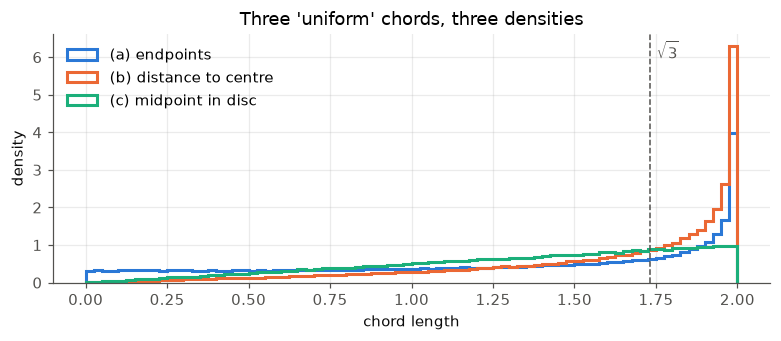

In [5]:
# Figure: the three chord laws, as histograms of chord length
fig, ax = plt.subplots(figsize=(7.2, 3.2))
t1, t2 = rng.uniform(0, 2*pi, 200_000), rng.uniform(0, 2*pi, 200_000)
Ls = {"(a) endpoints": 2*np.abs(np.sin((t1 - t2)/2)),
      "(b) distance to centre": 2*np.sqrt(1 - rng.uniform(0, 1, 200_000)**2),
      "(c) midpoint in disc": 2*np.sqrt(1 - rng.uniform(0, 1, 200_000))}
for (name, L), col in zip(Ls.items(), (C1, C2, C3)):
    ax.hist(L, bins=80, range=(0, 2), density=True, histtype="step", lw=2, color=col, label=name)
ax.axvline(sqrt(3), color="#52514e", lw=1, ls="--"); ax.text(sqrt(3)+0.02, ax.get_ylim()[1]*0.9, r"$\sqrt{3}$", color="#52514e")
ax.set_xlabel("chord length"); ax.set_ylabel("density"); ax.set_title("Three 'uniform' chords, three densities")
ax.legend(); plt.show()

## 2. A random variable is a function; a density is a rate

### A4 — A density can exceed 1; a probability cannot

$\mathcal N(0,\sigma)$ at zero has density $1/(\sigma\sqrt{2\pi})$, which passes 1 as soon as $\sigma < 0.399$ and
reaches about 40 at $\sigma = 0.01$. The probability of landing within $\pm 0.01$ stays below 1. A density is
probability *per unit length*; a log-density (a model's `log_prob`) can therefore be positive, and a likelihood
"greater than one" is not a bug.

In [6]:
sec("A4", "A density is not a probability: N(0, sigma) at 0, and P(|X| < 0.01) for sigma = 0.1")
for s in (1.0, 0.1, 0.01):
    print(f"sigma = {s:<5}: density at 0 = {1/(s*sqrt(2*pi)):8.3f};  P(|X| < 0.01) = {2*Phi(0.01/s) - 1:.4f}")
print(
    "the density exceeds 1 as soon as sigma < 1/sqrt(2 pi) = 0.3989; a probability never does; the density is a rate (probability per unit length)"
)


=== A4 A density is not a probability: N(0, sigma) at 0, and P(|X| < 0.01) for sigma = 0.1 ===
sigma = 1.0  : density at 0 =    0.399;  P(|X| < 0.01) = 0.0080
sigma = 0.1  : density at 0 =    3.989;  P(|X| < 0.01) = 0.0797
sigma = 0.01 : density at 0 =   39.894;  P(|X| < 0.01) = 0.6827
the density exceeds 1 as soon as sigma < 1/sqrt(2 pi) = 0.3989; a probability never does; the density is a rate (probability per unit length)


### A5 — Change of variables: the Jacobian is not optional

For $X \sim \mathcal N(0,1)$ and $Y = e^X$, the density of $Y$ is $\varphi(\log y)/y$. The $1/y$ is $|dx/dy|$; drop it and
the "density" integrates to $1.65$ (the printed $1.6471$; it is $\mathbb E[e^X]$, since $\varphi(\log y)$ integrates to $e^{1/2}$). Normalising flows are this identity composed many times, and the
log-determinant term in their loss is this $1/y$. The last line is Jensen: $\mathbb E[e^X] = e^{1/2} \ne e^{\mathbb E X} = 1$.
The histogram is normalised by the *whole* sample and the bin width — `np.histogram(..., density=True)` would normalise by the
$96\%$ of the mass that falls inside the plotted range $[0.05, 6]$ and sit about $4\%$ too high in every bin, a systematic
$0.026$ at the mode that looks like, and is not, sampling noise.

In [7]:
sec(
    "A5",
    "Change of variables: X ~ N(0,1), Y = exp(X). The density of Y is phi(log y)/y — the 1/y is |dx/dy|; without it the 'density' integrates to 1.65, not 1",
)
X = rng.standard_normal(2_000_000)
Y = np.exp(X)
counts, edges = np.histogram(Y, bins=np.linspace(0.05, 6, 120))
h = counts / (
    len(Y) * np.diff(edges)
)  # normalised by the whole sample, not by the 96.2% of it inside [0.05, 6] (density=True would do the latter)
c = 0.5 * (edges[1:] + edges[:-1])
phi = np.exp(-np.log(c) ** 2 / 2) / sqrt(2 * pi)
print(
    f"max |hist - phi(log y)/y| over 120 bins = {np.max(np.abs(h - phi/c)):.4f}   (sampling noise);  max |hist - phi(log y)| (Jacobian forgotten) = {np.max(np.abs(h - phi)):.4f}"
)
grid = np.linspace(1e-4, 60, 2_000_000)
dy = grid[1] - grid[0]
print(
    f"integral of phi(log y)/y dy over (0, 60] = {np.sum(np.exp(-np.log(grid)**2/2)/sqrt(2*pi)/grid)*dy:.4f};  integral of phi(log y) dy = {np.sum(np.exp(-np.log(grid)**2/2)/sqrt(2*pi))*dy:.4f}"
)
print(
    f"E[Y] = e^(1/2) = {exp(0.5):.4f}, sample {Y.mean():.4f};  exp(E[X]) = 1.0000 — Jensen: E[g(X)] >= g(E[X]) for convex g"
)


=== A5 Change of variables: X ~ N(0,1), Y = exp(X). The density of Y is phi(log y)/y — the 1/y is |dx/dy|; without it the 'density' integrates to 1.65, not 1 ===
max |hist - phi(log y)/y| over 120 bins = 0.0095   (sampling noise);  max |hist - phi(log y)| (Jacobian forgotten) = 0.4521


integral of phi(log y)/y dy over (0, 60] = 1.0000;  integral of phi(log y) dy = 1.6471
E[Y] = e^(1/2) = 1.6487, sample 1.6474;  exp(E[X]) = 1.0000 — Jensen: E[g(X)] >= g(E[X]) for convex g


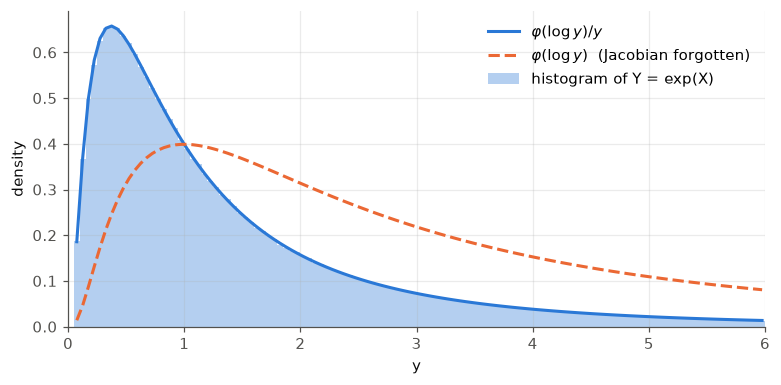

In [8]:
# Figure: the histogram of Y against the right density and the density with the Jacobian forgotten
fig, ax = plt.subplots()
ax.bar(c, h, width=edges[1]-edges[0], color=C1, alpha=0.35, label="histogram of Y = exp(X)")
ax.plot(c, phi/c, color=C1, lw=2, label=r"$\varphi(\log y)/y$")
ax.plot(c, phi, color=C2, lw=2, ls="--", label=r"$\varphi(\log y)$  (Jacobian forgotten)")
ax.set_xlim(0, 6); ax.set_xlabel("y"); ax.set_ylabel("density"); ax.legend(); plt.show()

## 3. Expectation is linear; everything else needs a hypothesis

### A6 — Linearity needs no independence; additivity of variance does

$\mathbb E[D_1 + D_2] = 7$ whether the dice are independent or the *same* die counted twice. The variance of the sum
is $2 \cdot 35/12$ in the first case and $4 \cdot 35/12$ in the second. Every "the expected total is the sum of the
expected parts" argument — expected loss over a batch, expected reward over an episode — is licensed by this cell;
every "the variance of the total is the sum of the variances" is not, until independence is checked.

In [9]:
sec(
    "A6",
    "Expectation is linear WITHOUT independence: E[X+Y] for the two dice (dependent copies too); variance is not",
)
d1, d2 = rng.integers(1, 7, N), rng.integers(1, 7, N)
print(
    f"independent dice: E[D1+D2] = {np.mean(d1+d2):.4f} (= 3.5+3.5);  Var(D1+D2) = {np.var(d1+d2):.4f} (= 2 * 35/12 = {2*35/12:.4f})"
)
print(
    f"same die twice:   E[D1+D1] = {np.mean(2*d1):.4f} (= 3.5+3.5);  Var(D1+D1) = {np.var(2*d1):.4f} (= 4 * 35/12 = {4*35/12:.4f}) — linearity held, additivity of variance did not"
)


=== A6 Expectation is linear WITHOUT independence: E[X+Y] for the two dice (dependent copies too); variance is not ===
independent dice: E[D1+D2] = 6.9973 (= 3.5+3.5);  Var(D1+D2) = 5.8344 (= 2 * 35/12 = 5.8333)
same die twice:   E[D1+D1] = 6.9998 (= 3.5+3.5);  Var(D1+D1) = 11.6925 (= 4 * 35/12 = 11.6667) — linearity held, additivity of variance did not


### A7 — Uncorrelated is not independent

$Y = X^2$ has zero correlation with $X$ and is a deterministic function of it. Correlation sees only the linear
part; the second number — $P(Y > 1 \mid |X| > 1) = 1$ against $P(Y>1) \approx 0.32$ — sees the dependence.

In [10]:
sec("A7", "Uncorrelated is not independent: X ~ N(0,1), Y = X^2")
X = rng.standard_normal(N)
Y = X**2
print(
    f"corr(X, Y) = {np.corrcoef(X, Y)[0,1]:+.4f};  but P(Y > 1 | |X| > 1) = {np.mean(Y[np.abs(X)>1] > 1):.4f} vs P(Y > 1) = {np.mean(Y > 1):.4f}  -> dependent"
)


=== A7 Uncorrelated is not independent: X ~ N(0,1), Y = X^2 ===
corr(X, Y) = -0.0016;  but P(Y > 1 | |X| > 1) = 1.0000 vs P(Y > 1) = 0.3168  -> dependent


### A8 — Pairwise independent is not mutually independent

Two fair bits and their XOR: every pair is independent, the triple is not, because the third is determined by the
other two. Pairwise checks (a correlation matrix, a mutual-information matrix) cannot see a dependence that only
appears in triples.

In [11]:
sec("A8", "Pairwise independent is not mutually independent: X, Y fair bits, Z = X xor Y")
X = rng.integers(0, 2, N)
Y = rng.integers(0, 2, N)
Z = X ^ Y
print(
    f"P(X=1,Z=1) = {np.mean((X==1)&(Z==1)):.4f} = P(X=1)P(Z=1) = {np.mean(X==1)*np.mean(Z==1):.4f};  P(Y=1,Z=1) = {np.mean((Y==1)&(Z==1)):.4f}"
)
print(
    f"P(X=1,Y=1,Z=1) = {np.mean((X==1)&(Y==1)&(Z==1)):.4f}  vs product {np.mean(X==1)*np.mean(Y==1)*np.mean(Z==1):.4f}  -> not mutually independent (Z is determined by X, Y)"
)


=== A8 Pairwise independent is not mutually independent: X, Y fair bits, Z = X xor Y ===
P(X=1,Z=1) = 0.2498 = P(X=1)P(Z=1) = 0.2502;  P(Y=1,Z=1) = 0.2503
P(X=1,Y=1,Z=1) = 0.0000  vs product 0.1253  -> not mutually independent (Z is determined by X, Y)


## 4. Conditioning is a projection

### A9 — Bayes with a base rate

A 95%-sensitive, 95%-specific test at 1% prevalence gives a positive result that is right about 16% of the time:
0.0095 true positives per 0.0495 false positives. The table scans prevalence; the last line shows two independent
positives. A classifier's precision on a deployment distribution is this calculation with the deployment prior,
not the training prior.

In [12]:
sec(
    "A9",
    "Bayes' rule with a base rate: prevalence 1%, sensitivity 95%, specificity 95% (a 5% false-positive rate)",
)
prev, sens, spec = 0.01, 0.95, 0.95
ppv = prev * sens / (prev * sens + (1 - prev) * (1 - spec))
print(f"P(disease | positive) = {ppv:.4f}  — 0.0095 true positives per 0.0495 false positives")
for prev in (0.001, 0.01, 0.1, 0.5):
    print(
        f"prevalence {prev:5.3f}: posterior after one positive = {prev*sens/(prev*sens + (1-prev)*(1-spec)):.4f}"
    )
print(f"two positives, conditionally independent given disease status, at prevalence 1%: -> {0.01*sens**2/(0.01*sens**2 + 0.99*(1-spec)**2):.4f}")


=== A9 Bayes' rule with a base rate: prevalence 1%, sensitivity 95%, specificity 95% (a 5% false-positive rate) ===
P(disease | positive) = 0.1610  — 0.0095 true positives per 0.0495 false positives
prevalence 0.001: posterior after one positive = 0.0187
prevalence 0.010: posterior after one positive = 0.1610
prevalence 0.100: posterior after one positive = 0.6786
prevalence 0.500: posterior after one positive = 0.9500
two positives, conditionally independent given disease status, at prevalence 1%: -> 0.7848


### A10 — Monty Hall: the host's *rule* is the model

The host who always opens a goat door makes switching win $2/3$. The host who opens a random unpicked door, and
happened to show a goat, makes it $1/2$. Same observation, different likelihood, different posterior. The
conditioning event is not "a goat was shown"; it is "a goat was shown *by this procedure*".

In [13]:
sec("A10", "Monty Hall as a conditioning statement: the host's RULE is the model")
car = rng.integers(0, 3, N)
pick = np.zeros(N, dtype=int)
print(
    f"host always opens a goat door: stay wins = {np.mean(car == pick):.4f}, switch wins = {np.mean(car != pick):.4f}   (1/3, 2/3)"
)
# host opens a random other door; keep only runs where it showed a goat
opened = rng.integers(1, 3, N)
goat_shown = opened != car
print(
    f"host opens a random unpicked door, condition on 'it was a goat': stay wins = {np.mean((car == pick)[goat_shown]):.4f}, switch wins = {np.mean((car != pick)[goat_shown]):.4f}   (1/2, 1/2)"
)


=== A10 Monty Hall as a conditioning statement: the host's RULE is the model ===
host always opens a goat door: stay wins = 0.3331, switch wins = 0.6669   (1/3, 2/3)


host opens a random unpicked door, condition on 'it was a goat': stay wins = 0.4996, switch wins = 0.5004   (1/2, 1/2)


### A11 — The conditional mean is the MSE-optimal predictor, by orthogonality

With $m(X) = \mathbb E[Y \mid X]$, the residual $Y - m(X)$ has zero covariance with *every* function of $X$ tried — $X$,
$X^2$, $\sin 3X$, an indicator — which is the projection theorem in $L^2$. Pythagoras follows: MSE(linear) =
MSE($m$) + $\mathbb E[(m - \text{linear})^2]$, to four decimals. Any other function of $X$ does worse than $m$, including
$m + 0.1X$. This is why a regression trained with squared loss is estimating a conditional mean, not a trend.

In [14]:
sec(
    "A11",
    "Conditional expectation is the MSE-optimal predictor, and its residual is orthogonal to every function of X",
)
X = rng.standard_normal(N)
eps = 0.5 * rng.standard_normal(N)
m = X**2 + np.sin(3 * X)
Y = m + eps
A = np.column_stack([np.ones(N), X])
beta = np.linalg.lstsq(A, Y, rcond=None)[0]
lin = A @ beta
for name, g in (("X", X), ("X^2", X**2), ("sin 3X", np.sin(3 * X)), ("1[X>0]", (X > 0).astype(float))):
    print(f"E[(Y - E[Y|X]) * {name:7}] = {np.mean((Y - m)*g):+.4f}")
print(
    f"MSE of best linear predictor = {np.mean((Y-lin)**2):.4f};  MSE of E[Y|X] = {np.mean((Y-m)**2):.4f} (= noise var 0.25);  E[(E[Y|X] - linear)^2] = {np.mean((m-lin)**2):.4f};  sum = {np.mean((Y-m)**2)+np.mean((m-lin)**2):.4f}"
)
# a WRONG predictor that is a function of X can't beat m
print(f"MSE of m(X) + 0.1*X (any other function of X) = {np.mean((Y - (m + 0.1*X))**2):.4f} > 0.25")


=== A11 Conditional expectation is the MSE-optimal predictor, and its residual is orthogonal to every function of X ===


E[(Y - E[Y|X]) * X      ] = -0.0010
E[(Y - E[Y|X]) * X^2    ] = +0.0006
E[(Y - E[Y|X]) * sin 3X ] = +0.0002
E[(Y - E[Y|X]) * 1[X>0] ] = +0.0001
MSE of best linear predictor = 2.7510;  MSE of E[Y|X] = 0.2500 (= noise var 0.25);  E[(E[Y|X] - linear)^2] = 2.5011;  sum = 2.7512
MSE of m(X) + 0.1*X (any other function of X) = 0.2602 > 0.25


### A12 — Cross-entropy's minimiser is the conditional probability

At a fixed input with $P(Y=1 \mid x) = 0.7$, the expected $-\log q$ is minimised at $q = 0.7$, where it equals the
entropy $H(0.7)$; the excess above that is $\mathrm{KL}(p\,\|\,q)$. So the population minimiser of cross-entropy is
*calibrated by theorem* — and a trained model's distance from it is an estimate, which is what calibration curves
measure. (The W41 Information Domain package is this identity taken further.)

In [15]:
sec(
    "A12",
    "Cross-entropy's population minimiser is the conditional probability: fixed x with P(Y=1|x) = 0.7, expected -log q as q varies",
)
p = 0.7
for q in (0.5, 0.6, 0.7, 0.8, 0.9, 0.99):
    print(
        f"q = {q:4}: E[-log q(Y)] = {-(p*log(q) + (1-p)*log(1-q)):.4f}  (minimum at q = p: H(p) = {-(p*log(p)+(1-p)*log(1-p)):.4f} nats)"
    )
print(
    "the gap E[-log q] - H(p) = KL(p || q): the minimiser is calibrated BY THEOREM; a trained model's distance from it is an estimate"
)


=== A12 Cross-entropy's population minimiser is the conditional probability: fixed x with P(Y=1|x) = 0.7, expected -log q as q varies ===
q =  0.5: E[-log q(Y)] = 0.6931  (minimum at q = p: H(p) = 0.6109 nats)
q =  0.6: E[-log q(Y)] = 0.6325  (minimum at q = p: H(p) = 0.6109 nats)
q =  0.7: E[-log q(Y)] = 0.6109  (minimum at q = p: H(p) = 0.6109 nats)
q =  0.8: E[-log q(Y)] = 0.6390  (minimum at q = p: H(p) = 0.6109 nats)
q =  0.9: E[-log q(Y)] = 0.7645  (minimum at q = p: H(p) = 0.6109 nats)
q = 0.99: E[-log q(Y)] = 1.3886  (minimum at q = p: H(p) = 0.6109 nats)
the gap E[-log q] - H(p) = KL(p || q): the minimiser is calibrated BY THEOREM; a trained model's distance from it is an estimate


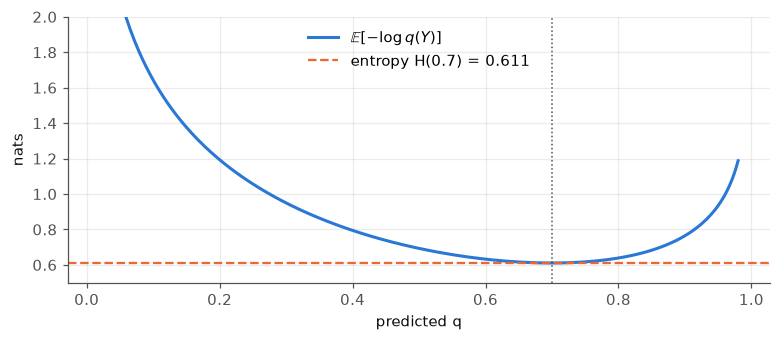

In [16]:
# Figure: the cross-entropy bowl, with its minimum at the true conditional probability
qs = np.linspace(0.02, 0.98, 300); ce = -(p*np.log(qs) + (1-p)*np.log(1-qs)); H = -(p*log(p) + (1-p)*log(1-p))
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(qs, ce, color=C1, lw=2, label=r"$\mathbb{E}[-\log q(Y)]$")
ax.axhline(H, color=C2, lw=1.5, ls="--", label=f"entropy H(0.7) = {H:.3f}")
ax.axvline(p, color="#52514e", lw=1, ls=":"); ax.set_xlabel("predicted q"); ax.set_ylabel("nats")
ax.set_ylim(0.5, 2); ax.legend(); plt.show()

### A13 — Total variance: aleatoric plus epistemic

$\mathrm{Var}(Y) = \mathbb E[\mathrm{Var}(Y\mid\theta)] + \mathrm{Var}(\mathbb E[Y\mid\theta])$: noise that no amount of knowledge about
$\theta$ removes, plus spread that comes from not knowing $\theta$. Every "uncertainty decomposition" in Bayesian
deep learning and every ensemble-disagreement score is this one line with a model in place of $\theta$.

In [17]:
sec(
    "A13",
    "Law of total variance = aleatoric + epistemic: Y = theta + noise, theta ~ N(0, tau^2), noise sd 0.5",
)
tau = 1.0
th = tau * rng.standard_normal(N)
Y = th + 0.5 * rng.standard_normal(N)
print(f"Var(Y) = {np.var(Y):.4f} = E[Var(Y|theta)] {0.25:.4f} + Var(E[Y|theta]) {np.var(th):.4f}")


=== A13 Law of total variance = aleatoric + epistemic: Y = theta + noise, theta ~ N(0, tau^2), noise sd 0.5 ===
Var(Y) = 1.2497 = E[Var(Y|theta)] 0.2500 + Var(E[Y|theta]) 1.0011


### A14 — Simpson's paradox is conditioning on a third variable

Women are admitted at a higher rate in both departments and a lower rate overall, because they applied to the
harder department. The sign of an effect can depend on what you condition on; an aggregate metric across
subgroups of different size and difficulty (a benchmark average, a per-language win rate) is this table.

In [18]:
sec(
    "A14",
    "Simpson's paradox: an aggregate that reverses both parts (Berkeley-style admissions numbers, made up to be clean)",
)
# dept A: men 80/100 admitted, women 90/100; dept B: men 10/100, women 15/300 -> aggregate
mA, wA, mB, wB = (80, 100), (90, 100), (10, 100), (36, 300)
print(
    f"dept A: men {mA[0]/mA[1]:.2f}  women {wA[0]/wA[1]:.2f};  dept B: men {mB[0]/mB[1]:.2f}  women {wB[0]/wB[1]:.2f}  (women ahead in both)"
)
print(
    f"aggregate: men {(mA[0]+mB[0])/(mA[1]+mB[1]):.3f}  women {(wA[0]+wB[0])/(wA[1]+wB[1]):.3f}  (men ahead overall) — the department is the stratifying variable; conditioning on it reverses the sign"
)


=== A14 Simpson's paradox: an aggregate that reverses both parts (Berkeley-style admissions numbers, made up to be clean) ===
dept A: men 0.80  women 0.90;  dept B: men 0.10  women 0.12  (women ahead in both)
aggregate: men 0.450  women 0.315  (men ahead overall) — the department is the stratifying variable; conditioning on it reverses the sign


## 5. The two limit theorems, and three failures

### A15 — The law of large numbers, with its ladder

One path of a fair coin's running mean, read at $n = 10, \dots, 10^6$, with the deviation and the standard-error
scale $1/(2\sqrt n)$ beside it. The deviation shrinks at that rate — and not faster. The next cell shows the same
rate on a Monte Carlo estimate of $\pi$.

In [19]:
sec(
    "A15",
    "Laws of large numbers: fair-coin running mean at n = 10..10^6 (one path), and the standard-error ladder 1/(2 sqrt n)",
)
coins = rng.integers(0, 2, 1_000_000)
cs = np.cumsum(coins)
for n in (10, 100, 1_000, 10_000, 100_000, 1_000_000):
    print(
        f"n = {n:>9,}: running mean = {cs[n-1]/n:.4f}   |dev| = {abs(cs[n-1]/n - 0.5):.4f}   1/(2 sqrt n) = {0.5/sqrt(n):.4f}"
    )


=== A15 Laws of large numbers: fair-coin running mean at n = 10..10^6 (one path), and the standard-error ladder 1/(2 sqrt n) ===
n =        10: running mean = 0.5000   |dev| = 0.0000   1/(2 sqrt n) = 0.1581
n =       100: running mean = 0.5300   |dev| = 0.0300   1/(2 sqrt n) = 0.0500
n =     1,000: running mean = 0.4930   |dev| = 0.0070   1/(2 sqrt n) = 0.0158
n =    10,000: running mean = 0.4985   |dev| = 0.0015   1/(2 sqrt n) = 0.0050
n =   100,000: running mean = 0.5006   |dev| = 0.0006   1/(2 sqrt n) = 0.0016
n = 1,000,000: running mean = 0.5000   |dev| = 0.0000   1/(2 sqrt n) = 0.0005


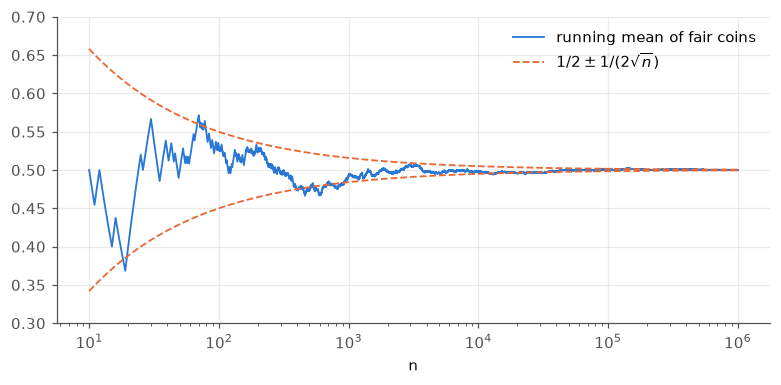

In [20]:
# Figure: one running-mean path inside its 1/(2 sqrt n) band
ns = np.arange(1, 1_000_001); fig, ax = plt.subplots()
ax.plot(ns[9:], cs[9:]/ns[9:], color=C1, lw=1.2, label="running mean of fair coins")
ax.plot(ns[9:], 0.5 + 0.5/np.sqrt(ns[9:]), color=C2, lw=1.2, ls="--", label=r"$1/2 \pm 1/(2\sqrt{n})$")
ax.plot(ns[9:], 0.5 - 0.5/np.sqrt(ns[9:]), color=C2, lw=1.2, ls="--")
ax.set_xscale("log"); ax.set_ylim(0.3, 0.7); ax.set_xlabel("n"); ax.legend(); plt.show()

### A16 — Monte Carlo and its error bar

Darts in a square: $\hat\pi$ at $n = 10^2, 10^4, 10^6$ with the CLT's 95% half-width, $1.96 \cdot 4\sqrt{\hat p(1-\hat p)/n}$.
The error shrinks as $1/\sqrt n$ — a hundred times more samples buy one more decimal — and the interval is the
honest statement of what the estimate knows.

In [21]:
sec("A16", "Monte Carlo: pi by throwing darts — error shrinks as 1/sqrt n, and the error bar is the CLT's")
for n in (100, 10_000, 1_000_000):
    u = rng.uniform(-1, 1, (n, 2))
    inside = np.sum(u**2, 1) <= 1
    est = 4 * inside.mean()
    se = 4 * sqrt(inside.mean() * (1 - inside.mean()) / n)
    print(f"n = {n:>9,}: pi_hat = {est:.4f}  ± {1.96*se:.4f} (95%)   |error| = {abs(est - pi):.4f}")


=== A16 Monte Carlo: pi by throwing darts — error shrinks as 1/sqrt n, and the error bar is the CLT's ===
n =       100: pi_hat = 2.8400  ± 0.3557 (95%)   |error| = 0.3016
n =    10,000: pi_hat = 3.1608  ± 0.0319 (95%)   |error| = 0.0192
n = 1,000,000: pi_hat = 3.1415  ± 0.0032 (95%)   |error| = 0.0001


### A17 — When the mean does not exist, the sample mean looks like a noisy estimate

St Petersburg ($2^K$ for a geometric $K$) has infinite expectation; its sample mean grows like $\log_2 n$ (Feller: $S_n/(n\log_2 n) \to 1$ in probability, slowly) and never
settles. The Cauchy has no mean; its sample mean is Cauchy *for every $n$*. Both print numbers that look like
estimates. The median of the Cauchy sample does converge — a law of large numbers is a property of the
statistic, not of the data.

In [22]:
sec("A17", "Infinite expectations look like noisy estimates: St Petersburg (2^K) and Cauchy running means")
K = rng.geometric(0.5, 1_000_000)
pay = 2.0**K
print(
    "St Petersburg sample mean at n = 10^2..10^6:",
    [round(float(pay[:k].mean()), 1) for k in (100, 1000, 10000, 100000, 1000000)],
    " (theory: grows like log2(n) — Feller: S_n/(n log2 n) -> 1 in probability)",
)
c = rng.standard_cauchy(1_000_000)
print(
    "Cauchy running mean at n = 10^2..10^6:      ",
    [round(float(c[:k].mean()), 3) for k in (100, 1000, 10000, 100000, 1000000)],
    " (never settles: S_n/n is Cauchy for every n)",
)
print(
    f"Cauchy sample MEDIAN at n = 10^6: {np.median(c):+.4f}  (the median has a law of large numbers; the mean does not)"
)


=== A17 Infinite expectations look like noisy estimates: St Petersburg (2^K) and Cauchy running means ===
St Petersburg sample mean at n = 10^2..10^6: [19.3, 11.0, 11.4, 25.4, 52.2]  (theory: grows like log2(n) — Feller: S_n/(n log2 n) -> 1 in probability)
Cauchy running mean at n = 10^2..10^6:       [0.547, 1.887, 0.819, 0.725, -2.613]  (never settles: S_n/n is Cauchy for every n)
Cauchy sample MEDIAN at n = 10^6: -0.0006  (the median has a law of large numbers; the mean does not)


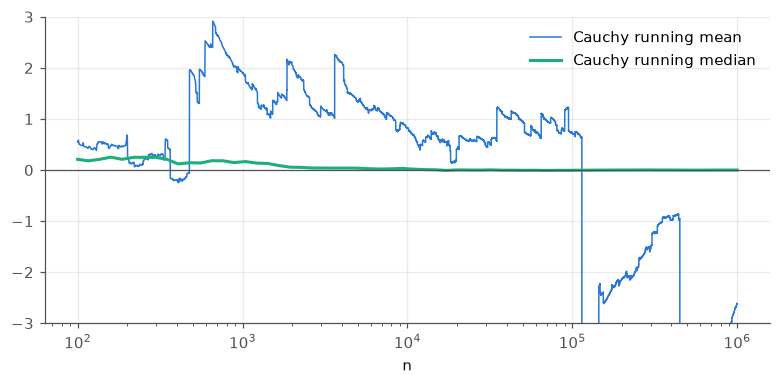

In [23]:
# Figure: two running means that never settle, and one running median that does
ns = np.arange(1, 1_000_001); fig, ax = plt.subplots()
ax.plot(ns[99:], np.cumsum(c)[99:]/ns[99:], color=C1, lw=1, label="Cauchy running mean")
sub = np.unique(np.logspace(2, 6, 60).astype(int))
ax.plot(sub, [np.median(c[:k]) for k in sub], color=C3, lw=2, label="Cauchy running median")
ax.axhline(0, color="#52514e", lw=0.8); ax.set_xscale("log"); ax.set_xlabel("n"); ax.set_ylim(-3, 3); ax.legend(); plt.show()

### A18 — Borel–Kolmogorov: the great circle conditioned two ways

A uniform point on the sphere, conditioned on lying on a great circle. Approach the circle by latitude bands and
the conditional law is uniform along it; approach the *same* circle by longitude bands (it is a meridian in rotated
axes) and the law is proportional to $\cos(\text{lat})$. The event has probability zero, and "given the event" is
undefined until you say which σ-algebra the conditioning lives in. Part II, `§6`, repeats this with the flagship's
sampler.

In [24]:
sec(
    "A18",
    "The great circle (Borel–Kolmogorov): conditioning a uniform point on the sphere on an event of probability zero, two limits",
)
z = rng.uniform(-1, 1, 4_000_000)
lon = rng.uniform(-pi, pi, 4_000_000)
lat = np.arcsin(z)
eps_ = 0.02
band = np.abs(lat) < eps_
h, _ = np.histogram(lon[band], bins=6, range=(-pi, pi))
print(f"(i) equator via latitude band:  longitude histogram (6 bins) = {h/h.sum()}  -> uniform")
band = np.abs(lon) < eps_
h, edges = np.histogram(lat[band], bins=6, range=(-pi / 2, pi / 2))
cen = 0.5 * (edges[1:] + edges[:-1])
print(
    f"(ii) meridian via longitude band: latitude histogram (6 bins)  = {h/h.sum()}  vs cos(lat) normalised = {np.cos(cen)/np.cos(cen).sum()}"
)


=== A18 The great circle (Borel–Kolmogorov): conditioning a uniform point on the sphere on an event of probability zero, two limits ===


(i) equator via latitude band:  longitude histogram (6 bins) = [0.1678 0.1647 0.1663 0.1689 0.1669 0.1653]  -> uniform
(ii) meridian via longitude band: latitude histogram (6 bins)  = [0.0664 0.1818 0.2526 0.2516 0.1821 0.0655]  vs cos(lat) normalised = [0.067 0.183 0.25  0.25  0.183 0.067]


---
# Part II — The Probability Domain, `§1`–`§14`

These are the flagship's own sections, under the flagship's seed. Several revisit an experiment from Part I with a
different sampler or a different normalisation; the articles quote each one, so both are kept.

### §1 — Bertrand's chord, the flagship's run

The same three measures as `A3`, one million chords each, so the two articles can quote their own tables.

In [25]:
sec(1, "Bertrand's chord: three 'uniform' measures, three answers (unit circle, side = sqrt(3))")
N = 1_000_000
# (a) random endpoints
t1, t2 = rng.uniform(0, 2 * pi, N), rng.uniform(0, 2 * pi, N)
L = 2 * np.abs(np.sin((t1 - t2) / 2))
pa = np.mean(L > sqrt(3))
print(f"(a) two uniform endpoints        P(L > sqrt3) = {pa:.4f}   (theory 1/3 = {1/3:.4f})")
# (b) random radius point: distance from centre uniform on [0,1]
d = rng.uniform(0, 1, N)
L = 2 * np.sqrt(1 - d**2)
pb = np.mean(L > sqrt(3))
print(f"(b) uniform distance to centre   P(L > sqrt3) = {pb:.4f}   (theory 1/2 = {0.5:.4f})")
# (c) random midpoint uniform in the disc
r = np.sqrt(rng.uniform(0, 1, N))
L = 2 * np.sqrt(1 - r**2)
pc = np.mean(L > sqrt(3))
print(f"(c) uniform midpoint in the disc P(L > sqrt3) = {pc:.4f}   (theory 1/4 = {0.25:.4f})")
print(
    f"(SE of the three lines above: ± {sqrt(pa*(1-pa)/N):.4f}, ± {sqrt(pb*(1-pb)/N):.4f}, ± {sqrt(pc*(1-pc)/N):.4f} — binomial sqrt(p(1-p)/N) at N = {N:,}; the largest |measured - theory| is {max(abs(pa-1/3)/sqrt(pa*(1-pa)/N), abs(pb-0.5)/sqrt(pb*(1-pb)/N), abs(pc-0.25)/sqrt(pc*(1-pc)/N)):.1f} SE)"
)


=== §1 Bertrand's chord: three 'uniform' measures, three answers (unit circle, side = sqrt(3)) ===
(a) two uniform endpoints        P(L > sqrt3) = 0.3324   (theory 1/3 = 0.3333)
(b) uniform distance to centre   P(L > sqrt3) = 0.4994   (theory 1/2 = 0.5000)
(c) uniform midpoint in the disc P(L > sqrt3) = 0.2491   (theory 1/4 = 0.2500)
(SE of the three lines above: ± 0.0005, ± 0.0005, ± 0.0004 — binomial sqrt(p(1-p)/N) at N = 1,000,000; the largest |measured - theory| is 2.0 SE)


### §2 — Monty Hall as a conditioning statement

The flagship's one-line version: with a host who always shows a goat, "stay" is the event $\{\text{car} = \text{pick}\}$
and the simulation does not even need to model the door that was opened.

In [26]:
sec(2, "Monty Hall as a conditioning statement")
N = 1_000_000
car = rng.integers(0, 3, N)
pick = rng.integers(0, 3, N)
ps = np.mean(car == pick)
print(f"stay wins   = {ps:.4f}   switch wins = {1-ps:.4f}   (theory 1/3, 2/3)")
print(
    f"(SE of the line above: ± {sqrt(ps*(1-ps)/N):.4f} for either frequency — binomial sqrt(p(1-p)/N) at N = {N:,})"
)


=== §2 Monty Hall as a conditioning statement ===
stay wins   = 0.3332   switch wins = 0.6668   (theory 1/3, 2/3)
(SE of the line above: ± 0.0005 for either frequency — binomial sqrt(p(1-p)/N) at N = 1,000,000)


### §3 — Lebesgue versus Riemann on the indicator of the rationals

No sampling here, only the statement: the rationals in $[0,1]$ are dense yet of measure zero, so their indicator has
Lebesgue integral 0 and no Riemann integral at all. Lebesgue builds the integral from the *range*; that is what
makes expectation a single definition for discrete, continuous and mixed laws, and what makes "almost
everywhere" a usable phrase.

In [27]:
sec(
    3,
    "Vitali-free but still sharp: a dense set of measure zero (rationals in [0,1]) — the Lebesgue integral of 1_Q",
)
# Riemann: upper sum 1, lower sum 0 on every partition; Lebesgue: measure of Q is 0.
print("Riemann upper sum = 1, lower sum = 0 on every partition -> not Riemann integrable")
print("Lebesgue: lambda(Q cap [0,1]) = 0  ->  integral of 1_Q = 0  (a countable union of points)")
print(
    "Lebesgue builds the integral from the RANGE (level sets), Riemann from the DOMAIN (intervals): that is the whole difference"
)


=== §3 Vitali-free but still sharp: a dense set of measure zero (rationals in [0,1]) — the Lebesgue integral of 1_Q ===
Riemann upper sum = 1, lower sum = 0 on every partition -> not Riemann integrable
Lebesgue: lambda(Q cap [0,1]) = 0  ->  integral of 1_Q = 0  (a countable union of points)
Lebesgue builds the integral from the RANGE (level sets), Riemann from the DOMAIN (intervals): that is the whole difference


### §4 — Example E2: the Bayes risk of a Gaussian mixture, and how fast logistic regression reaches it

Two classes at $\pm\mu e_1$ with identity covariance: the Bayes risk is $\Phi(-\mu)$, checked by Monte Carlo. Logistic
regression fitted by Newton on $n = 50, \dots, 20{,}000$ points in $d = 20$ approaches it from above; the excess over
Bayes is the price of estimation. E2 returns in notebook 01, `§21`, where SGD is run on it with four step schedules.

In [28]:
sec(
    4,
    "E2 — two-class Gaussian mixture, means ±mu e1, identity covariance, equal priors: Bayes risk = Phi(-mu)",
)
for mu in (0.5, 1.0, 1.5, 2.0):
    print(f"mu = {mu:.1f}:  Bayes risk Phi(-mu) = {Phi(-mu):.4f}")
mu, dsz, n = 1.0, 20, 200_000
y = rng.integers(0, 2, n) * 2 - 1
X = rng.standard_normal((n, dsz))
X[:, 0] += mu * y
print(f"Monte Carlo Bayes classifier error at mu=1, d={dsz}, n={n:,}: {np.mean(np.sign(X[:,0]) != y):.4f}")


# logistic regression by Newton on 2,000 points, 20 dims; then its test error vs Bayes
def fit_logreg(X, y, iters=25, l2=1e-3):
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        z = (y + 1) / 2
        g = X.T @ (p - z) / len(y) + l2 * w
        H = (X.T * (p * (1 - p))) @ X / len(y) + l2 * np.eye(X.shape[1])
        w -= np.linalg.solve(H, g)
    return w


for ntr in (50, 200, 2000, 20000):
    Xtr, ytr = X[:ntr], y[:ntr]
    w = fit_logreg(Xtr, ytr)
    err = np.mean(np.sign(X[20000:] @ w) != y[20000:])
    print(
        f"logistic regression, n_train={ntr:>6}, d=20: held-out error {err:.4f}  (excess over Bayes {err-Phi(-mu):+.4f})"
    )


=== §4 E2 — two-class Gaussian mixture, means ±mu e1, identity covariance, equal priors: Bayes risk = Phi(-mu) ===
mu = 0.5:  Bayes risk Phi(-mu) = 0.3085
mu = 1.0:  Bayes risk Phi(-mu) = 0.1587
mu = 1.5:  Bayes risk Phi(-mu) = 0.0668
mu = 2.0:  Bayes risk Phi(-mu) = 0.0228


Monte Carlo Bayes classifier error at mu=1, d=20, n=200,000: 0.1586
logistic regression, n_train=    50, d=20: held-out error 0.2551  (excess over Bayes +0.0965)
logistic regression, n_train=   200, d=20: held-out error 0.1920  (excess over Bayes +0.0334)
logistic regression, n_train=  2000, d=20: held-out error 0.1629  (excess over Bayes +0.0042)


logistic regression, n_train= 20000, d=20: held-out error 0.1581  (excess over Bayes -0.0005)


### §5 — Conditional expectation as an $L^2$ projection

The flagship's version of `A11`: orthogonality of the residual against four test functions, then Pythagoras for
the mean-squared errors. The conditional mean is the closest function of $X$ to $Y$, in the geometry where
distance is root-mean-square.

In [29]:
sec(
    5, "Conditional expectation is an L2 projection: E[(Y - E[Y|X]) g(X)] = 0 for every g, and MSE decomposes"
)
n = 1_000_000
Xc = rng.standard_normal(n)
Y = Xc**2 + np.sin(3 * Xc) + 0.5 * rng.standard_normal(n)
m = Xc**2 + np.sin(3 * Xc)  # E[Y|X] exactly
resid = Y - m
for name, g in (("X", Xc), ("X^2", Xc**2), ("sin 3X", np.sin(3 * Xc)), ("1[X>0]", (Xc > 0).astype(float))):
    print(f"E[(Y - E[Y|X]) * {name:7s}] = {np.mean(resid*g):+.4f}")
f_lin = np.polyfit(Xc, Y, 1)
pred = np.polyval(f_lin, Xc)
print(f"MSE of best LINEAR predictor      = {np.mean((Y-pred)**2):.4f}")
print(f"MSE of E[Y|X]                     = {np.mean((Y-m)**2):.4f}   (= noise variance 0.25)")
print(
    f"E[(E[Y|X] - linear)^2]            = {np.mean((m-pred)**2):.4f}   -> sum {np.mean((Y-m)**2)+np.mean((m-pred)**2):.4f} (Pythagoras)"
)


=== §5 Conditional expectation is an L2 projection: E[(Y - E[Y|X]) g(X)] = 0 for every g, and MSE decomposes ===


E[(Y - E[Y|X]) * X      ] = -0.0002
E[(Y - E[Y|X]) * X^2    ] = +0.0003
E[(Y - E[Y|X]) * sin 3X ] = -0.0001
E[(Y - E[Y|X]) * 1[X>0] ] = -0.0004


MSE of best LINEAR predictor      = 2.7392
MSE of E[Y|X]                     = 0.2497   (= noise variance 0.25)
E[(E[Y|X] - linear)^2]            = 2.4885   -> sum 2.7382 (Pythagoras)


### §6 — Borel–Kolmogorov with a Gaussian sampler

The great circle again (`A18`), now with points drawn as normalised Gaussian vectors. The two conditional laws
differ exactly as before — uniform along the equator, $\cos(\text{lat})$ along the meridian — which confirms the
effect is about the conditioning, not the sampler.

In [30]:
sec(6, "Borel–Kolmogorov: conditioning a uniform point on the sphere on a great circle, two ways")
n = 4_000_000
v = rng.standard_normal((n, 3))
v /= np.linalg.norm(v, axis=1, keepdims=True)
lat = np.arcsin(v[:, 2])
lon = np.arctan2(v[:, 1], v[:, 0])
eps = 0.02
# (i) the great circle as the equator: band |lat| < eps -> distribution of longitude
sel = np.abs(lat) < eps
h, _ = np.histogram(lon[sel], bins=6, range=(-pi, pi))
print(f"(i) equator via latitude band:  longitude histogram (6 bins, normalised) = {h/h.sum()}")
# (ii) the same great circle as a meridian (rotate axes): band |lon| < eps -> distribution of latitude
sel = np.abs(lon) < eps
h, edges = np.histogram(lat[sel], bins=6, range=(-pi / 2, pi / 2))
centres = (edges[:-1] + edges[1:]) / 2
print(f"(ii) meridian via longitude band: latitude histogram (6 bins, normalised) = {h/h.sum()}")
print(
    f"     cos(latitude) at bin centres, normalised                             = {np.cos(centres)/np.cos(centres).sum()}"
)
print(
    "Same curve on the sphere, two conditional densities: uniform in (i), proportional to cos(lat) in (ii)."
)


=== §6 Borel–Kolmogorov: conditioning a uniform point on the sphere on a great circle, two ways ===


(i) equator via latitude band:  longitude histogram (6 bins, normalised) = [0.1659 0.1707 0.1645 0.1664 0.1645 0.168 ]
(ii) meridian via longitude band: latitude histogram (6 bins, normalised) = [0.0665 0.1833 0.2528 0.2468 0.1876 0.0631]
     cos(latitude) at bin centres, normalised                             = [0.067 0.183 0.25  0.25  0.183 0.067]
Same curve on the sphere, two conditional densities: uniform in (i), proportional to cos(lat) in (ii).


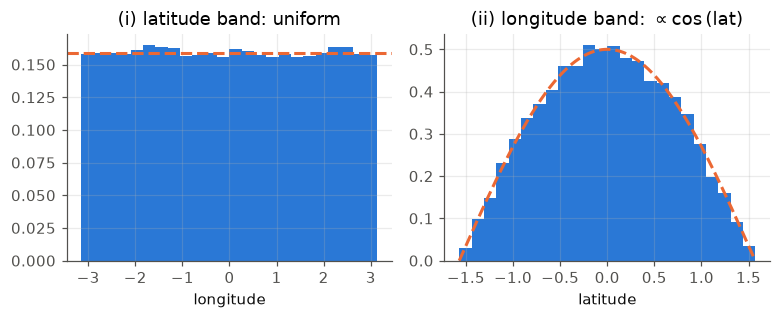

In [31]:
# Figure: the two conditional laws on the same great circle
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
selA = np.abs(lat) < eps; a1.hist(lon[selA], bins=24, range=(-pi, pi), density=True, color=C1)
a1.axhline(1/(2*pi), color=C2, lw=2, ls="--"); a1.set_title("(i) latitude band: uniform"); a1.set_xlabel("longitude")
selB = np.abs(lon) < eps; a2.hist(lat[selB], bins=24, range=(-pi/2, pi/2), density=True, color=C1)
g = np.linspace(-pi/2, pi/2, 200); a2.plot(g, np.cos(g)/2, color=C2, lw=2, ls="--"); a2.set_title(r"(ii) longitude band: $\propto\cos$(lat)"); a2.set_xlabel("latitude")
plt.show()

## The four convergences

### §7 — The typewriter sequence and escaping mass

Two counter-examples that separate the modes of convergence. The *typewriter*: indicators of dyadic intervals
enumerated level by level; $P(X_n = 1) \to 0$ (convergence in probability and in $L^1$) while every sample point is
hit once per level, so $\limsup X_n = 1$ everywhere — no almost-sure convergence. *Escaping mass*: $X_n = n\,\mathbf
1[U < 1/n]$ goes to 0 in probability while $\mathbb E[X_n] = 1$ forever — no $L^1$ convergence. The first is why
"the loss converged in probability" does not imply any single run converged; the second is why a vanishing
probability of a huge value still moves the mean.

In [32]:
sec(7, "Modes of convergence: the typewriter sequence and escaping mass")
# typewriter: indicator of [k/2^m, (k+1)/2^m) enumerated; X_n(u) -> 0 in probability and in L1, but limsup = 1 for every u.
u = rng.uniform(0, 1, 100_000)
hits = np.zeros_like(u)
idx = 0
pm = []
for m in range(0, 12):
    for k in range(2**m):
        Xn = ((u >= k / 2**m) & (u < (k + 1) / 2**m)).astype(float)
        pm.append((idx, Xn.mean()))
        hits += Xn
        idx += 1
print(
    f"typewriter: P(X_n = 1) at n = 1, 3, 7, 1023, 4095: {[round(float(pm[i][1]),4) for i in (0,2,6,1022,4094)]}  -> 0"
)
print(
    f"typewriter: fraction of sample points u hit at least once per dyadic level (12 levels): {np.mean(hits >= 12):.4f}  -> limsup X_n = 1 a.s."
)
print(
    f"(SE of the P(X_n = 1) line: each entry is a frequency over the {len(u):,} points u, ± sqrt(p(1-p)/{len(u):,}) = "
    + ", ".join(f"{sqrt(pm[i][1]*(1-pm[i][1])/len(u)):.4f}" for i in (0, 2, 6, 1022, 4094))
    + "; the 1.0000 is exact — every u is hit at every level)"
)
# escaping mass: X_n = n * 1[U < 1/n]
esc7 = []
for nn in (10, 100, 1000, 10000):
    Xn = nn * (u < 1 / nn)
    print(
        f"escaping mass n={nn:>5}: P(X_n != 0) = {np.mean(Xn != 0):.4f}, E[X_n] = {Xn.mean():.3f}  (-> 0 in probability, E stays 1: no L1 convergence)"
    )
    esc7.append((nn, np.mean(Xn != 0)))
print(
    "(SE of the four lines above, from the same "
    + f"{len(u):,}"
    + " points: P(X_n != 0) ± "
    + ", ".join(f"{sqrt(q*(1-q)/len(u)):.4f}" for _, q in esc7)
    + ";  E[X_n] = n · P(X_n != 0) here, so ± "
    + ", ".join(f"{nn*sqrt(q*(1-q)/len(u)):.3f}" for nn, q in esc7)
    + " — the E[X_n] column is a mean of 100,000 terms of which only n^-1 of them are nonzero, which is why it wanders while its expectation is exactly 1)"
)


=== §7 Modes of convergence: the typewriter sequence and escaping mass ===


typewriter: P(X_n = 1) at n = 1, 3, 7, 1023, 4095: [1.0, 0.5014, 0.2523, 0.0021, 0.0006]  -> 0
typewriter: fraction of sample points u hit at least once per dyadic level (12 levels): 1.0000  -> limsup X_n = 1 a.s.
(SE of the P(X_n = 1) line: each entry is a frequency over the 100,000 points u, ± sqrt(p(1-p)/100,000) = 0.0000, 0.0016, 0.0014, 0.0001, 0.0001; the 1.0000 is exact — every u is hit at every level)
escaping mass n=   10: P(X_n != 0) = 0.0997, E[X_n] = 0.997  (-> 0 in probability, E stays 1: no L1 convergence)
escaping mass n=  100: P(X_n != 0) = 0.0104, E[X_n] = 1.039  (-> 0 in probability, E stays 1: no L1 convergence)
escaping mass n= 1000: P(X_n != 0) = 0.0011, E[X_n] = 1.110  (-> 0 in probability, E stays 1: no L1 convergence)
escaping mass n=10000: P(X_n != 0) = 0.0001, E[X_n] = 1.400  (-> 0 in probability, E stays 1: no L1 convergence)
(SE of the four lines above, from the same 100,000 points: P(X_n != 0) ± 0.0009, 0.0003, 0.0001, 0.0000;  E[X_n] = n · P(X_n != 0) here

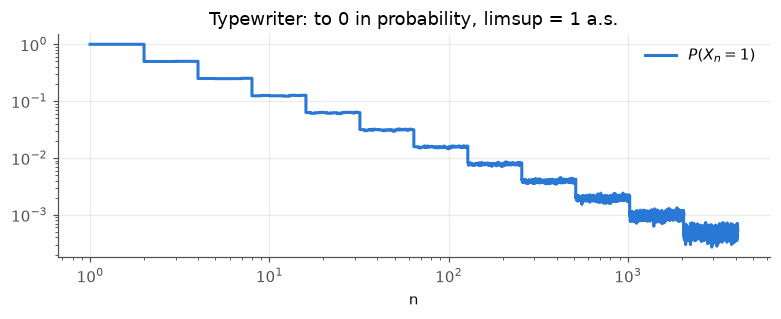

In [33]:
# Figure: the typewriter's P(X_n = 1) decays stepwise while every point keeps being hit
idxs = np.array([i for i, _ in pm]); probs = np.array([v for _, v in pm])
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.step(idxs + 1, probs, where="post", color=C1, lw=2, label=r"$P(X_n = 1)$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n"); ax.legend(); ax.set_title("Typewriter: to 0 in probability, limsup = 1 a.s."); plt.show()

### §8 — Strong law versus the law of the iterated logarithm

Two million fair coins. The running mean's deviation from $1/2$ stays inside the LIL envelope
$\sigma\sqrt{2\log\log n / n}$ at all but $0.007\%$ of the $n \ge 100$ on this path, crosses half the envelope $26\%$ of the time, and
crosses the CLT-width band $\sigma/\sqrt n$ $39\%$ of the time. The CLT describes one $n$; the LIL describes the whole
path, and the ratio between them — $\sqrt{2\log\log n}$, $2.3$ at $n = 10^6$ — is the price of asking about every
$n$ at once. Notebook 01 `§22` turns this into the peeking problem.

In [34]:
sec(8, "SLLN vs LIL: how far a running mean of fair coins strays, against sqrt(2 log log n / n) * sigma")
n = 2_000_000
flips = rng.integers(0, 2, n)
S = np.cumsum(flips - 0.5)
ns = np.arange(1, n + 1)
mask = ns >= 100
env = 0.5 * np.sqrt(2 * np.log(np.log(ns[mask])) / ns[mask])  # sigma = 1/2 for a fair coin
dev = np.abs(S[mask]) / ns[mask]
print(f"fraction of n in [100, 2e6] with |S_n/n| > LIL envelope: {np.mean(dev > env):.5f}")
print(f"fraction of n in [100, 2e6] with |S_n/n| > 0.5*envelope : {np.mean(dev > 0.5*env):.4f}")
print(
    f"fraction of n in [100, 2e6] with |S_n/n| > 1/sqrt(n)*0.5 (a CLT-width band): {np.mean(dev > 0.5/np.sqrt(ns[mask])):.4f}"
)
for nn in (100, 1_000, 10_000, 100_000, 1_000_000):
    print(
        f"n={nn:>9}: envelope = {0.5*sqrt(2*log(log(nn))/nn):.5f}   1/sqrt(n) CLT scale = {0.5/sqrt(nn):.5f}   ratio = {sqrt(2*log(log(nn))):.3f}"
    )


=== §8 SLLN vs LIL: how far a running mean of fair coins strays, against sqrt(2 log log n / n) * sigma ===
fraction of n in [100, 2e6] with |S_n/n| > LIL envelope: 0.00007
fraction of n in [100, 2e6] with |S_n/n| > 0.5*envelope : 0.2615
fraction of n in [100, 2e6] with |S_n/n| > 1/sqrt(n)*0.5 (a CLT-width band): 0.3947
n=      100: envelope = 0.08738   1/sqrt(n) CLT scale = 0.05000   ratio = 1.748
n=     1000: envelope = 0.03109   1/sqrt(n) CLT scale = 0.01581   ratio = 1.966
n=    10000: envelope = 0.01054   1/sqrt(n) CLT scale = 0.00500   ratio = 2.107
n=   100000: envelope = 0.00350   1/sqrt(n) CLT scale = 0.00158   ratio = 2.211
n=  1000000: envelope = 0.00115   1/sqrt(n) CLT scale = 0.00050   ratio = 2.292


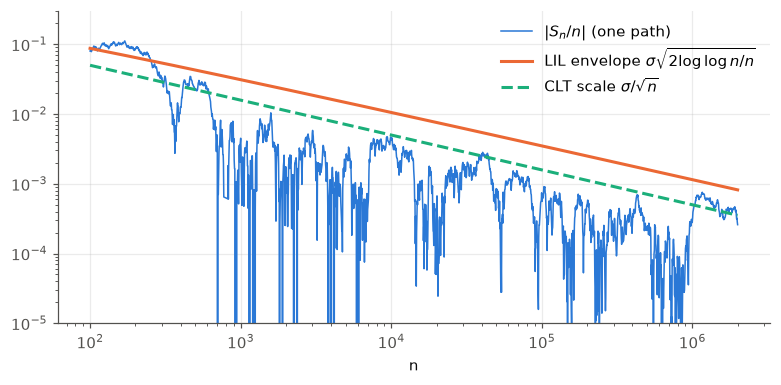

In [35]:
# Figure: |S_n/n| on a log-spaced subsample against the LIL envelope and the CLT scale
sub = np.unique(np.logspace(2, np.log10(n), 2000).astype(int))
fig, ax = plt.subplots()
ax.plot(sub, np.abs(S[sub-1])/sub, color=C1, lw=1, label=r"$|S_n/n|$ (one path)")
ax.plot(sub, 0.5*np.sqrt(2*np.log(np.log(sub))/sub), color=C2, lw=2, label=r"LIL envelope $\sigma\sqrt{2\log\log n/n}$")
ax.plot(sub, 0.5/np.sqrt(sub), color=C3, lw=2, ls="--", label=r"CLT scale $\sigma/\sqrt{n}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-5, 0.3); ax.set_xlabel("n"); ax.legend(loc="upper right"); plt.show()

## The central limit theorem, as a Fourier statement

### §9 — Berry–Esseen against the exact binomial

The theorem says $\sup_x |F_n(x) - \Phi(x)| \le 0.4748\,\rho/(\sigma^3\sqrt n)$. The left side is computed exactly from the
binomial CDF, the right side from the formula. For a fair coin at $n = 30$ the bound ($0.087$) sits 20% above the
measurement ($0.072$) — *loose but true*; at $p = 0.01$ the ratio $\rho/\sigma^3$ is $9.9$, $n = 300$ is three expected events,
and the measured distance is $0.147$ — the CLT has barely started. The rate the theorem controls is in *expected events*, not in samples.

In [36]:
sec(
    9,
    "Berry–Esseen for Bernoulli(p) sums: the bound 0.4748 * rho / (sigma^3 sqrt n) against the measured sup distance",
)
for p, nn in ((0.5, 30), (0.1, 30), (0.1, 300), (0.01, 300)):
    sig = sqrt(p * (1 - p))
    rho = p * (1 - p) * ((1 - p) ** 2 + p**2)  # E|X-p|^3
    bound = 0.4748 * rho / (sig**3 * sqrt(nn))
    # exact binomial CDF of standardised sum vs Phi
    from math import comb

    ks = np.arange(nn + 1)
    pmf = np.array([comb(nn, k) * p**k * (1 - p) ** (nn - k) for k in ks])
    cdf = np.cumsum(pmf)
    z = (ks - nn * p) / (sig * sqrt(nn))
    supd = max(
        max(abs(cdf[i] - Phi(z[i])) for i in range(nn + 1)),
        max(abs(cdf[i - 1] - Phi(z[i])) for i in range(1, nn + 1)),
    )
    print(
        f"p={p:<5} n={nn:>4}: measured sup|F_n - Phi| = {supd:.4f}   Berry–Esseen bound = {bound:.4f}   (rho/sigma^3 = {rho/sig**3:.3f})"
    )


=== §9 Berry–Esseen for Bernoulli(p) sums: the bound 0.4748 * rho / (sigma^3 sqrt n) against the measured sup distance ===
p=0.5   n=  30: measured sup|F_n - Phi| = 0.0722   Berry–Esseen bound = 0.0867   (rho/sigma^3 = 1.000)
p=0.1   n=  30: measured sup|F_n - Phi| = 0.1474   Berry–Esseen bound = 0.2369   (rho/sigma^3 = 2.733)
p=0.1   n= 300: measured sup|F_n - Phi| = 0.0484   Berry–Esseen bound = 0.0749   (rho/sigma^3 = 2.733)
p=0.01  n= 300: measured sup|F_n - Phi| = 0.1472   Berry–Esseen bound = 0.2701   (rho/sigma^3 = 9.851)


### §10 — The empirical characteristic function of a standardised sum

For sums of 50 exponentials, standardised, $\mathbb E[e^{itZ}]$ is measured over $200{,}000$ replicates and compared with
$e^{-t^2/2}$ at $t = 0.5, 1, 2$. The real parts match to the third decimal; the imaginary parts are the residual skew,
and the skewness of $Z$ is $\gamma_1/\sqrt n$ to the same precision. The CLT *is* this: a product of $n$ characteristic
functions, each $1 - t^2/(2n) + o(1/n)$, converging to a Gaussian's. The W38 Fourier package and this one meet here.

In [37]:
sec(
    10,
    "The CLT is a Fourier theorem: empirical characteristic function of the standardised sum vs exp(-t^2/2)",
)
nn, reps = 50, 200_000
Xs = rng.exponential(1.0, (reps, nn))
Z = (Xs.sum(1) - nn) / sqrt(nn)
se10 = []
for t in (0.5, 1.0, 2.0):
    ecf = np.mean(np.exp(1j * t * Z))
    print(
        f"t={t}: |empirical cf| = {abs(ecf):.4f}, Re = {ecf.real:+.4f}, Im = {ecf.imag:+.4f};  exp(-t^2/2) = {exp(-t*t/2):.4f}"
    )
    se10.append((t, np.std(np.cos(t * Z)) / sqrt(reps), np.std(np.sin(t * Z)) / sqrt(reps)))
print(
    "(SE of the three lines above, sd/sqrt("
    + f"{reps:,}"
    + ") of cos(tZ) and sin(tZ): "
    + ";  ".join(f"t={t}: Re ± {a:.4f}, Im ± {b:.4f}" for t, a, b in se10)
    + " — the Im parts sit "
    + ", ".join(f"{abs(np.mean(np.sin(t*Z)))/b:.1f}" for t, a, b in se10)
    + " SE from 0: at n = 50 the exponential sum is still skewed, which the next line measures)"
)
print(
    f"skewness of standardised sum (n=50 exponentials): {np.mean(Z**3):.4f}  (theory gamma1/sqrt(n) = {2/sqrt(nn):.4f})"
)
print(f"(SE of the line above: ± {np.std(Z**3)/sqrt(reps):.4f}, sd(Z^3)/sqrt({reps:,}))")


=== §10 The CLT is a Fourier theorem: empirical characteristic function of the standardised sum vs exp(-t^2/2) ===
t=0.5: |empirical cf| = 0.8823, Re = +0.8822, Im = -0.0050;  exp(-t^2/2) = 0.8825
t=1.0: |empirical cf| = 0.6080, Re = +0.6073, Im = -0.0290;  exp(-t^2/2) = 0.6065


t=2.0: |empirical cf| = 0.1441, Re = +0.1341, Im = -0.0527;  exp(-t^2/2) = 0.1353


(SE of the three lines above, sd/sqrt(200,000) of cos(tZ) and sin(tZ): t=0.5: Re ± 0.0004, Im ± 0.0010;  t=1.0: Re ± 0.0010, Im ± 0.0015;  t=2.0: Re ± 0.0016, Im ± 0.0016 — the Im parts sit 5.1, 19.7, 33.4 SE from 0: at n = 50 the exponential sum is still skewed, which the next line measures)
skewness of standardised sum (n=50 exponentials): 0.2994  (theory gamma1/sqrt(n) = 0.2828)
(SE of the line above: ± 0.0095, sd(Z^3)/sqrt(200,000))


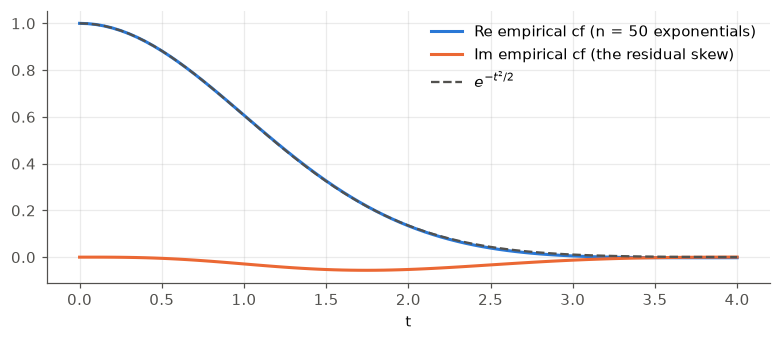

In [38]:
# Figure: the empirical characteristic function on a grid of t against the Gaussian's
ts = np.linspace(0, 4, 81); ecf = np.array([np.mean(np.exp(1j*t*Z)) for t in ts])
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(ts, ecf.real, color=C1, lw=2, label="Re empirical cf (n = 50 exponentials)")
ax.plot(ts, ecf.imag, color=C2, lw=2, label="Im empirical cf (the residual skew)")
ax.plot(ts, np.exp(-ts**2/2), color="#52514e", lw=1.5, ls="--", label=r"$e^{-t^2/2}$")
ax.set_xlabel("t"); ax.legend(); plt.show()

### §11 — Where the CLT fails

The Cauchy running mean at $n = 10^2 \dots 10^6$ wanders; Pareto with $\alpha = 1.5$ has a mean (3) but infinite
variance, so its block means have a sample mean near 3, a standard deviation that does not shrink as expected,
occasional enormous values and an excess kurtosis that grows with the sample instead of going to 0. The limit of
its standardised sums is a 1.5-stable law. Heavy-tailed gradients, reward outliers and per-token losses with
rare spikes are all in this regime, and the fix is not more samples; it is a different estimator.

In [39]:
sec(
    11,
    "Where the CLT fails: Cauchy means never settle; Pareto(alpha=1.5) has a mean but its standardised sum is not Gaussian",
)
c = rng.standard_cauchy(1_000_000)
print(
    "Cauchy running mean at n = 10^2..10^6:",
    [round(float(c[:k].mean()), 3) for k in (100, 1000, 10000, 100000, 1000000)],
)
alpha = 1.5
par = (rng.uniform(0, 1, (20_000, 1000))) ** (
    -1 / alpha
)  # Pareto with x_min=1, mean alpha/(alpha-1)=3, infinite variance
s = par.sum(1) / 1000
print(
    f"Pareto(1.5): sample means of blocks of 1000: mean {s.mean():.3f} (theory 3.000), sd {s.std():.3f}, max {s.max():.1f}"
)
print(
    f"(no standard error is printed for the line above: a block mean of Pareto(1.5) draws has infinite variance, so sd/sqrt({len(s):,}) = {s.std()/sqrt(len(s)):.4f} is a statistic of these {len(s):,} blocks with no population value behind it — §53 shows how far it moves between batches)"
)
zz = (s - s.mean()) / s.std()
print(
    f"excess kurtosis of the block means: {np.mean(zz**4)-3:.2f}  (a Gaussian limit would give ~0; it is diverging, the limit is 1.5-stable)"
)


=== §11 Where the CLT fails: Cauchy means never settle; Pareto(alpha=1.5) has a mean but its standardised sum is not Gaussian ===
Cauchy running mean at n = 10^2..10^6: [-1.135, -0.296, -0.331, -0.308, 0.022]


Pareto(1.5): sample means of blocks of 1000: mean 2.996 (theory 3.000), sd 1.772, max 227.7
(no standard error is printed for the line above: a block mean of Pareto(1.5) draws has infinite variance, so sd/sqrt(20,000) = 0.0125 is a statistic of these 20,000 blocks with no population value behind it — §53 shows how far it moves between batches)
excess kurtosis of the block means: 12930.89  (a Gaussian limit would give ~0; it is diverging, the limit is 1.5-stable)


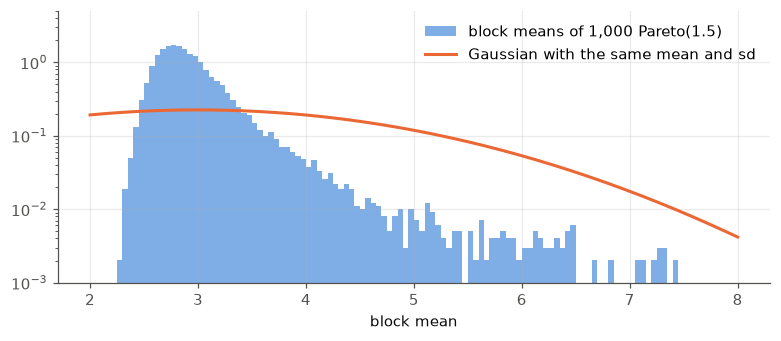

In [40]:
# Figure: Pareto(1.5) block means are not Gaussian — a log-scale histogram against the fitted normal
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.hist(s, bins=120, range=(2, 8), density=True, color=C1, alpha=0.6, label="block means of 1,000 Pareto(1.5)")
g = np.linspace(2, 8, 300); ax.plot(g, np.exp(-(g-s.mean())**2/(2*s.var()))/sqrt(2*pi*s.var()), color=C2, lw=2, label="Gaussian with the same mean and sd")
ax.set_yscale("log"); ax.set_ylim(1e-3, 5); ax.set_xlabel("block mean"); ax.legend(); plt.show()

## High dimensions, concentrated

### §12 — Example E3: Gaussian vectors in $d$ dimensions

The norm of a standard Gaussian vector is $\sqrt d$ give or take $1/\sqrt 2$ — *the same spread at every $d$* — so in
$d = 4096$ every vector lives on a thin shell at radius 64. The cosine between two independent vectors has standard
deviation $1/\sqrt d$; the dot product has standard deviation $\sqrt d$. Attention's $q\cdot k/\sqrt d$ is the second
fact: without the division, logits at $d_{\text{head}} = 64$ would have spread 8 and the softmax would saturate.

In [41]:
sec(12, "E3 — standard Gaussian vectors in d dimensions: norms, cosines, attention logits")
for d in (16, 256, 4096):
    G = rng.standard_normal((2000, d))
    nrm = np.linalg.norm(G, axis=1)
    cos = (G[:1000] * G[1000:]).sum(1) / (nrm[:1000] * nrm[1000:])
    dots = (G[:1000] * G[1000:]).sum(1)
    print(
        f"d={d:>5}: ||g|| mean {nrm.mean():8.3f} sd {nrm.std():.3f} (sqrt d = {sqrt(d):.3f}, sd -> 1/sqrt2 = 0.707);  "
        f"cosine sd {cos.std():.4f} (1/sqrt d = {1/sqrt(d):.4f});  dot-product sd {dots.std():.2f} (sqrt d = {sqrt(d):.2f})"
    )
    print(
        f"    (SE of the line above: ||g|| mean ± {nrm.std(ddof=1)/sqrt(len(nrm)):.3f}, its sd ± {se_sd(nrm):.3f};  cosine sd ± {se_sd(cos):.4f};  dot-product sd ± {se_sd(dots):.2f}   — from the same {len(nrm):,} vectors / {len(cos):,} pairs, SE(sd) = sqrt((m4 - s^4)/n)/(2 s))"
    )


=== §12 E3 — standard Gaussian vectors in d dimensions: norms, cosines, attention logits ===
d=   16: ||g|| mean    3.962 sd 0.683 (sqrt d = 4.000, sd -> 1/sqrt2 = 0.707);  cosine sd 0.2544 (1/sqrt d = 0.2500);  dot-product sd 4.11 (sqrt d = 4.00)
    (SE of the line above: ||g|| mean ± 0.015, its sd ± 0.011;  cosine sd ± 0.0052;  dot-product sd ± 0.10   — from the same 2,000 vectors / 1,000 pairs, SE(sd) = sqrt((m4 - s^4)/n)/(2 s))
d=  256: ||g|| mean   15.982 sd 0.713 (sqrt d = 16.000, sd -> 1/sqrt2 = 0.707);  cosine sd 0.0644 (1/sqrt d = 0.0625);  dot-product sd 16.57 (sqrt d = 16.00)
    (SE of the line above: ||g|| mean ± 0.016, its sd ± 0.011;  cosine sd ± 0.0014;  dot-product sd ± 0.38   — from the same 2,000 vectors / 1,000 pairs, SE(sd) = sqrt((m4 - s^4)/n)/(2 s))


d= 4096: ||g|| mean   64.020 sd 0.707 (sqrt d = 64.000, sd -> 1/sqrt2 = 0.707);  cosine sd 0.0157 (1/sqrt d = 0.0156);  dot-product sd 64.54 (sqrt d = 64.00)
    (SE of the line above: ||g|| mean ± 0.016, its sd ± 0.011;  cosine sd ± 0.0003;  dot-product sd ± 1.44   — from the same 2,000 vectors / 1,000 pairs, SE(sd) = sqrt((m4 - s^4)/n)/(2 s))


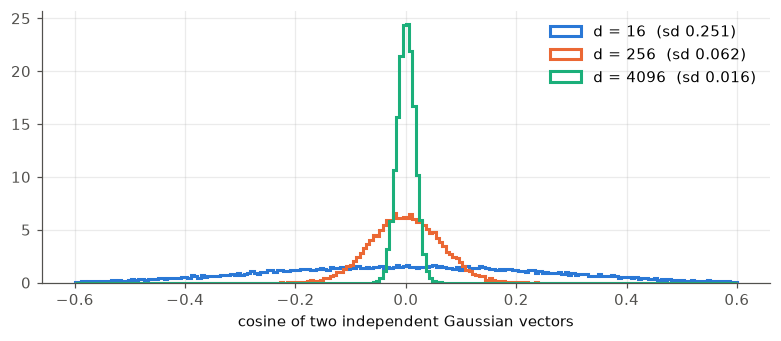

In [42]:
# Figure: the cosine between two random Gaussian vectors narrows as 1/sqrt(d)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for dd, col in zip((16, 256, 4096), (C1, C2, C3)):
    A_, B_ = rng.standard_normal((20000, dd)), rng.standard_normal((20000, dd))
    cs_ = (A_*B_).sum(1)/(np.linalg.norm(A_, axis=1)*np.linalg.norm(B_, axis=1))
    ax.hist(cs_, bins=200, range=(-0.6, 0.6), density=True, histtype="step", lw=2, color=col, label=f"d = {dd}  (sd {cs_.std():.3f})")
ax.set_xlabel("cosine of two independent Gaussian vectors"); ax.legend(); plt.show()

### §13 — Johnson–Lindenstrauss

A thousand points in $d = 4096$, projected by a Gaussian matrix scaled by $1/\sqrt k$: pairwise distances are preserved
to a ratio with standard deviation $\approx 1/\sqrt{2k}$ and a worst case that shrinks with $k$. The dimension of the
*data* never enters the guarantee — only the number of points, through the union bound — which is why random
projections, hashing tricks and sketching work at all.

In [43]:
sec(13, "Johnson–Lindenstrauss: 1,000 points in d=4096 projected to k dims by a Gaussian matrix / sqrt k")


def pdist(A):
    sq = (A * A).sum(1)
    D2 = sq[:, None] + sq[None, :] - 2 * A @ A.T
    return np.sqrt(np.maximum(D2, 0))


P = rng.standard_normal((1000, 4096))
D0 = pdist(P)
iu = np.triu_indices(1000, 1)
for k in (64, 256, 1024):
    R = rng.standard_normal((4096, k)) / sqrt(k)
    Q = P @ R
    D1 = pdist(Q)
    ratio = D1[iu] / D0[iu]
    print(
        f"k={k:>5}: distance ratio mean {ratio.mean():.4f}, sd {ratio.std():.4f}, max distortion {np.abs(ratio-1).max():.4f}   (theory sd ~ 1/sqrt(2k) = {1/sqrt(2*k):.4f})"
    )
    M13 = np.zeros((1000, 1000))
    M13[iu] = ratio
    M13 = M13 + M13.T  # delete-one-POINT jackknife: the 499,500 pairs share points
    S1, S2, T1, T2, Np = M13.sum(1), (M13 * M13).sum(1), ratio.sum(), (ratio * ratio).sum(), len(ratio)
    m_i = (T1 - S1) / (Np - 999)
    sd_i = np.sqrt(np.maximum((T2 - S2) / (Np - 999) - m_i**2, 0))
    jk13 = lambda th: sqrt(999 / 1000 * np.sum((th - th.mean()) ** 2))
    print(
        f"    (SE of the line above: ratio mean ± {jk13(m_i):.4f}, sd ± {jk13(sd_i):.4f}   — delete-one-point jackknife over the 1,000 points, since the 499,500 pairs share points; the max distortion is an extreme value, no SE)"
    )


=== §13 Johnson–Lindenstrauss: 1,000 points in d=4096 projected to k dims by a Gaussian matrix / sqrt k ===


k=   64: distance ratio mean 0.9947, sd 0.0861, max distortion 0.4061   (theory sd ~ 1/sqrt(2k) = 0.0884)
    (SE of the line above: ratio mean ± 0.0027, sd ± 0.0010   — delete-one-point jackknife over the 1,000 points, since the 499,500 pairs share points; the max distortion is an extreme value, no SE)
k=  256: distance ratio mean 0.9973, sd 0.0443, max distortion 0.2102   (theory sd ~ 1/sqrt(2k) = 0.0442)
    (SE of the line above: ratio mean ± 0.0014, sd ± 0.0005   — delete-one-point jackknife over the 1,000 points, since the 499,500 pairs share points; the max distortion is an extreme value, no SE)


k= 1024: distance ratio mean 0.9990, sd 0.0217, max distortion 0.1116   (theory sd ~ 1/sqrt(2k) = 0.0221)
    (SE of the line above: ratio mean ± 0.0007, sd ± 0.0002   — delete-one-point jackknife over the 1,000 points, since the 499,500 pairs share points; the max distortion is an extreme value, no SE)


### §14 — Covariance estimation at $d = 256$

$\|\hat\Sigma - I\|_{\text{op}}$ for $n = d/4$ to $64d$: the error tracks $\sqrt{d/n}$ (Vershynin, Theorem 4.7.1), and at $n = d/4$ the
sample covariance is not even full rank. Estimating a $d \times d$ covariance well needs $n \gg d$ samples, not $n \gg 1$;
every whitening, every Gaussian-process prior fitted from data, every second-order optimiser's curvature
estimate pays this rate.

In [44]:
sec(
    14,
    "Covariance estimation: ||Sigma_hat - I||_op for n = d/4, d, 4d, 16d, 64d at d=256 (Vershynin Thm 4.7.1 scale sqrt(d/n))",
)
d = 256
for f in (0.25, 1, 4, 16, 64):
    n = int(f * d)
    G = rng.standard_normal((n, d))
    Sh = G.T @ G / n
    op = np.max(np.abs(np.linalg.eigvalsh(Sh) - 1))
    print(
        f"n = {f:>5}d = {n:>6}: ||Sigma_hat - I||_op = {op:.3f}    sqrt(d/n) = {sqrt(d/n):.3f}   (2*sqrt(d/n)+d/n = {2*sqrt(d/n)+d/n:.3f})"
    )


=== §14 Covariance estimation: ||Sigma_hat - I||_op for n = d/4, d, 4d, 16d, 64d at d=256 (Vershynin Thm 4.7.1 scale sqrt(d/n)) ===
n =  0.25d =     64: ||Sigma_hat - I||_op = 7.741    sqrt(d/n) = 2.000   (2*sqrt(d/n)+d/n = 8.000)
n =     1d =    256: ||Sigma_hat - I||_op = 2.972    sqrt(d/n) = 1.000   (2*sqrt(d/n)+d/n = 3.000)
n =     4d =   1024: ||Sigma_hat - I||_op = 1.289    sqrt(d/n) = 0.500   (2*sqrt(d/n)+d/n = 1.250)
n =    16d =   4096: ||Sigma_hat - I||_op = 0.563    sqrt(d/n) = 0.250   (2*sqrt(d/n)+d/n = 0.562)
n =    64d =  16384: ||Sigma_hat - I||_op = 0.261    sqrt(d/n) = 0.125   (2*sqrt(d/n)+d/n = 0.266)


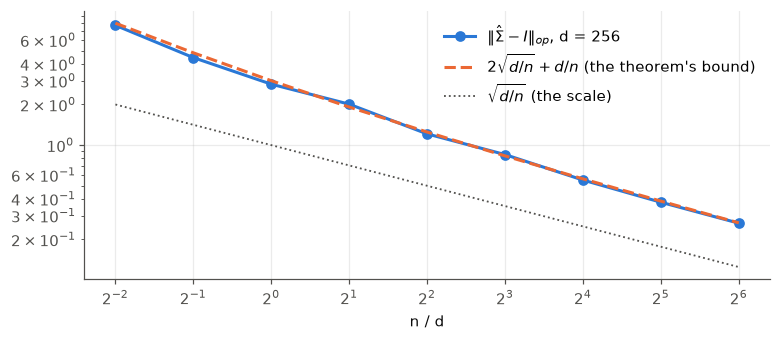

In [45]:
# Figure: operator-norm error of the sample covariance against sqrt(d/n)
fs = np.array([0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]); errs = []
for f_ in fs:
    n_ = int(f_*d); G_ = rng.standard_normal((n_, d)); errs.append(np.max(np.abs(np.linalg.eigvalsh(G_.T@G_/n_) - 1)))
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(fs, errs, "o-", color=C1, lw=2, ms=6, label=r"$\|\hat\Sigma - I\|_{op}$, d = 256")
ax.plot(fs, 2*np.sqrt(1/fs) + 1/fs, color=C2, lw=2, ls="--", label=r"$2\sqrt{d/n} + d/n$ (the theorem's bound)")
ax.plot(fs, np.sqrt(1/fs), color="#52514e", lw=1.2, ls=":", label=r"$\sqrt{d/n}$ (the scale)")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("n / d"); ax.legend(); plt.show()

---
## Summary of what was measured

| # | Claim | Where |
|---|---|---|
| 1 | A coarser σ-algebra asks fewer questions; the sum of two dice cannot see "first die is 6" | `A1` |
| 2 | Three uniform measures on chords, three answers: 1/3, 1/2, 1/4 | `A3`, `§1` |
| 3 | A density passes 1 at $\sigma < 0.399$; dropping a Jacobian makes a "density" integrate to 1.65 | `A4`, `A5` |
| 4 | Linearity of expectation holds without independence; additivity of variance does not | `A6` |
| 5 | Uncorrelated ≠ independent; pairwise ≠ mutual | `A7`, `A8` |
| 6 | The conditional mean's residual is orthogonal to every function of $X$, and Pythagoras holds for the MSEs | `A11`, `§5` |
| 7 | Cross-entropy's population minimiser is the conditional probability | `A12` |
| 8 | St Petersburg and Cauchy sample means never settle; the Cauchy median does | `A17`, `§11` |
| 9 | The typewriter converges in probability but not a.s.; escaping mass converges in probability but not in $L^1$ | `§7` |
| 10 | One path of $2\times10^6$ coins stays inside the LIL envelope; the CLT band is crossed far more often | `§8` |
| 11 | The empirical characteristic function of a standardised sum is $e^{-t^2/2}$ to three decimals; Berry–Esseen's bound holds and is loose | `§9`, `§10` |
| 12 | Norm $\sqrt d \pm 1/\sqrt2$, cosine sd $1/\sqrt d$, JL distortion $1/\sqrt{2k}$, covariance error $\sqrt{d/n}$ | `§12`–`§14` |
| 13 | The same great circle gives two conditional laws | `A18`, `§6` |

**Next:** [`01_concentration_and_chains.ipynb`](./01_concentration_and_chains.ipynb) — the error bar: concentration
inequalities against the exact binomial, interval coverage as a frequency, the eval-set and pairing tables,
selection bias, high-dimensional geometry, the peeking experiment, SGD as Robbins–Monro, and the AR(1), Metropolis,
Langevin and diffusion chains with their effective sample sizes.

---
*This notebook accompanies the Artifocial content series. Read the flagship at
[artifocial.com/blog/probability-domain-2026-oct-22](https://artifocial.com/blog/probability-domain-2026-oct-22), and see
what we build with these ideas at [artifocial.com/apps](https://artifocial.com/apps).*